In [13]:
import math

with open("aime_problems.json", "r") as f:
    aime_problems = json.load(f)

def is_aime24_problem(input_text):
    for problem in aime_problems["aime24"]:
        if problem in input_text:
            return True
    return False

def is_aime25_problem(input_text):
    for problem in aime_problems["aime25"]:
        if problem in input_text:
            return True
    return False

filter_func = is_aime25_problem

base_file_paths = [
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-16k-think_aime2425_512_luffy_step__25-11-15-Nov-11-1763143255/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-16k-think_aime2425_512_luffy_step__25-11-15-Nov-11-1763152408/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-16k-think_aime2425_512_luffy_step__25-11-15-Nov-11-1763155828/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-16k-think_aime2425_512_luffy_step__25-11-15-Nov-11-1763159266/0.jsonl"
]
sft_file_paths = [
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-SFT_aime2425_512_luffy_step__25-11-14-Nov-11-1763121249/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-SFT_aime2425_512_luffy_step__25-11-15-Nov-11-1763178296/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-SFT_aime2425_512_luffy_step__25-11-15-Nov-11-1763203067/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-SFT_aime2425_512_luffy_step__25-11-16-Nov-11-1763239655/0.jsonl"
]
rft_file_paths = [
    "/home/ma-user/work/hzy-dev/_results/eval_rft_baseline_aime2425_512_step_global_step_500_25-11-16-Nov-11-1763261202/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/eval_rft_baseline_aime2425_512_step_global_step_500_25-11-16-Nov-11-1763265067/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/eval_rft_baseline_aime2425_512_step_global_step_500_25-11-16-Nov-11-1763269031/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/eval_rft_baseline_aime2425_512_step_global_step_500_25-11-16-Nov-11-1763273029/0.jsonl"

]
luffy_file_paths = [
    "/home/ma-user/work/hzy-dev/_results/luffyeval_LUFFY-Qwen-Math-7B-Zero_aime2425_512_luffy_step__25-11-15-Nov-11-1763136772/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_LUFFY-Qwen-Math-7B-Zero_aime2425_512_luffy_step__25-11-15-Nov-11-1763212366/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_LUFFY-Qwen-Math-7B-Zero_aime2425_512_luffy_step__25-11-15-Nov-11-1763213316/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_LUFFY-Qwen-Math-7B-Zero_aime2425_512_luffy_step__25-11-15-Nov-11-1763216029/0.jsonl"
]
prft_file_paths = [
    "/home/ma-user/work/hzy-dev/_results/eval_prft_aime2425_512_step_global_step_500_25-11-14-Nov-11-1763060067/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/eval_prft_aime2425_512_step_global_step_500_25-11-15-Nov-11-1763162923/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/eval_prft_aime2425_512_step_global_step_500_25-11-15-Nov-11-1763187543/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/eval_prft_aime2425_512_step_global_step_500_25-11-16-Nov-11-1763224007/0.jsonl"
]
file_paths = rft_file_paths
# load all jsonl file and merge
import json
from collections import defaultdict
results = defaultdict(list)
merged_data = []
for file_path in file_paths:
    with open(file_path, 'r') as f:
        for line in f:
            d = json.loads(line)
            if filter_func(d['input']):
                merged_data.append(d)
                results[d['input']].append(d["score"])
print(len(merged_data))

def calculate_pass_at_k(c_list, n_samples, k_list):
    """
    根据论文 (arXiv:2504.13837v4) 附录 A.2 中的公式计算 pass@k 的无偏估计。

    参数:
    c_list (list): 一个整数列表。列表中的每个元素 c_i 对应一个问题，
                   表示该问题在 n_samples 个总样本中被正确解答的次数 。
    n_samples (int): 为每个问题生成的总样本数 (即公式中的 'n') 。
    k_list (list): 一个整数列表，包含所有需要计算 pass@k 的 k 值。

    返回:
    dict: 一个字典，键是 k 值，值是对应的 pass@k 分数。
    """
    
    # 检查 c_list 是否为空
    num_problems = len(c_list)
    if num_problems == 0:
        print("警告: c_list 为空，无法计算 pass@k。")
        return {}

    # 检查 c_list 中的值是否有效
    for c_i in c_list:
        if not isinstance(c_i, int) or c_i < 0 or c_i > n_samples:
            raise ValueError(
                f"c_list 中的值 ({c_i}) 必须是 0 到 n_samples ({n_samples}) 之间的整数。"
            )
            
    results = {}
    
    # 遍历所有需要计算的 k 值
    for k in k_list:
        if not isinstance(k, int) or k < 0:
            print(f"跳过无效的 k 值: {k} (必须是非负整数)")
            continue
            
        # 论文中规定 n >= k 。
        # 如果 k > n_samples，math.comb(n_samples, k) 会返回 0，导致除零错误。
        # pass@k 的定义也意味着 k 不能大于总样本数 n。
        if k > n_samples:
            print(f"跳过 k={k}，因为它大于总样本数 n_samples={n_samples}。")
            results[k] = None
            continue
        
        # k=0 时，pass@0 始终为 0
        if k == 0:
            results[k] = 0.0
            continue
            
        # 预先计算分母 C(n, k)
        try:
            denominator = math.comb(n_samples, k)
        except ValueError:
            print(f"计算 C({n_samples}, {k}) 出错。跳过 k={k}。")
            results[k] = None
            continue
            
        # 如果分母为0 (虽然 k <= n_samples 时不应发生)，跳过
        if denominator == 0:
            print(f"分母 C({n_samples}, {k}) 为 0。跳过 k={k}。")
            results[k] = None
            continue

        total_pass_at_k_for_dataset = 0.0
        
        # 遍历每个问题计算其 pass@k 
        for c_i in c_list:
            # c_i 是正确答案数，(n_samples - c_i) 是错误答案数
            num_incorrect = n_samples - c_i
            
            # 计算分子 C(n-c_i, k)，即从错误答案中抽取 k 个的组合数
            # math.comb 会自动处理 num_incorrect < k 的情况 (返回 0)
            numerator = math.comb(num_incorrect, k)
            
            # 计算单个问题的 pass@k： 1 - (C(n-c_i, k) / C(n, k)) 
            pass_at_k_for_problem = 1.0 - (numerator / denominator)
            
            # 累加到数据集中
            total_pass_at_k_for_dataset += pass_at_k_for_problem
            
        # 计算整个数据集的平均 pass@k 
        average_pass_at_k = total_pass_at_k_for_dataset / num_problems
        results[k] = average_pass_at_k
        
    return results

c_values = []
for k, v in results.items():
    c_values.append(int(sum(v)))

k_list = [
    1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048
]
pass_at_k_scores = calculate_pass_at_k(c_values, 512 * len(file_paths), k_list)


for k, v in pass_at_k_scores.items():
    print(f"pass@{k}: {v:.4f}")

61440
pass@1: 0.1215
pass@2: 0.1497
pass@4: 0.1843
pass@8: 0.2331
pass@16: 0.3036
pass@32: 0.3929
pass@64: 0.4831
pass@128: 0.5601
pass@256: 0.6163
pass@512: 0.6494
pass@1024: 0.6745
pass@2048: 0.7000


成功加载 'aime_problems.json'。
--- 未找到缓存文件 'all_pass_at_k_results.json'。将开始计算... ---
========= 开始计算 pass@k 分数 =========

--- Zz正在处理数据集: AIME 24 ---
计算模型: Base (Think)...
  ... 检查了 122880 行，找到 30 个匹配的问题。
  ... 已验证 30 个问题，每个问题有 2048 个样本。
计算模型: SFT...
  ... 检查了 122880 行，找到 30 个匹配的问题。
  ... 已验证 30 个问题，每个问题有 2048 个样本。
计算模型: RFT...
  ... 检查了 122880 行，找到 30 个匹配的问题。
  ... 已验证 30 个问题，每个问题有 2048 个样本。
计算模型: LUFFY...
  ... 检查了 122880 行，找到 30 个匹配的问题。
  ... 已验证 30 个问题，每个问题有 2048 个样本。
计算模型: PRFT...
  ... 检查了 122880 行，找到 30 个匹配的问题。
  ... 已验证 30 个问题，每个问题有 2048 个样本。

--- Zz正在处理数据集: AIME 25 ---
计算模型: Base (Think)...
  ... 检查了 122880 行，找到 30 个匹配的问题。
  ... 已验证 30 个问题，每个问题有 2048 个样本。
计算模型: SFT...
  ... 检查了 122880 行，找到 30 个匹配的问题。
  ... 已验证 30 个问题，每个问题有 2048 个样本。
计算模型: RFT...
  ... 检查了 122880 行，找到 30 个匹配的问题。
  ... 已验证 30 个问题，每个问题有 2048 个样本。
计算模型: LUFFY...
  ... 检查了 122880 行，找到 30 个匹配的问题。
  ... 已验证 30 个问题，每个问题有 2048 个样本。
计算模型: PRFT...
  ... 检查了 122880 行，找到 30 个匹配的问题。
  ... 已验证 30 个问题，每个问题有 2048 个样本。

========= 计算完

/tmp/ipykernel_1441258/583352132.py:336: UserWarning: Glyph 26679 (\N{CJK UNIFIED IDEOGRAPH-6837}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 0.82, 1])
/tmp/ipykernel_1441258/583352132.py:336: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 0.82, 1])
/tmp/ipykernel_1441258/583352132.py:336: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 0.82, 1])
/tmp/ipykernel_1441258/583352132.py:336: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 0.82, 1])
/tmp/ipykernel_1441258/583352132.py:336: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 0.82, 1])
/tmp/ipykernel_1441258/583352132.py:336: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu San

✅ 图表已保存为: AIME_24_pass_at_k.png

正在为 AIME 25 生成图表...


/tmp/ipykernel_1441258/583352132.py:336: UserWarning: Glyph 26679 (\N{CJK UNIFIED IDEOGRAPH-6837}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 0.82, 1])
/tmp/ipykernel_1441258/583352132.py:336: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 0.82, 1])
/tmp/ipykernel_1441258/583352132.py:336: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 0.82, 1])
/tmp/ipykernel_1441258/583352132.py:336: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 0.82, 1])
/tmp/ipykernel_1441258/583352132.py:336: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 0.82, 1])
/tmp/ipykernel_1441258/583352132.py:336: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu San

✅ 图表已保存为: AIME_25_pass_at_k.png

========= 脚本执行完毕 =========


/home/ma-user/work/hzy-dev/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ma-user/work/hzy-dev/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ma-user/work/hzy-dev/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ma-user/work/hzy-dev/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ma-user/work/hzy-dev/miniconda3/lib/python3.13/site-packages/I

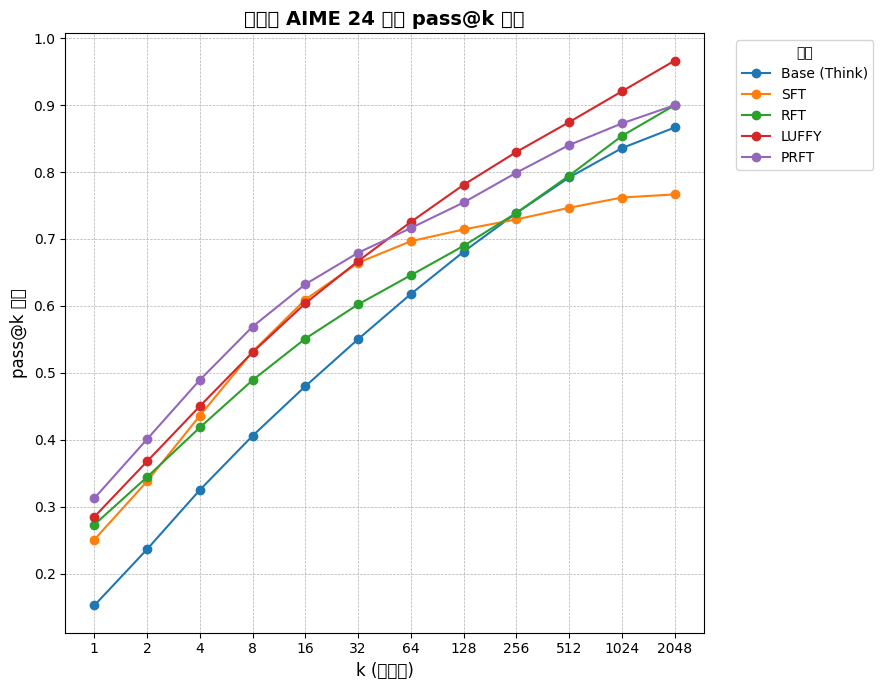

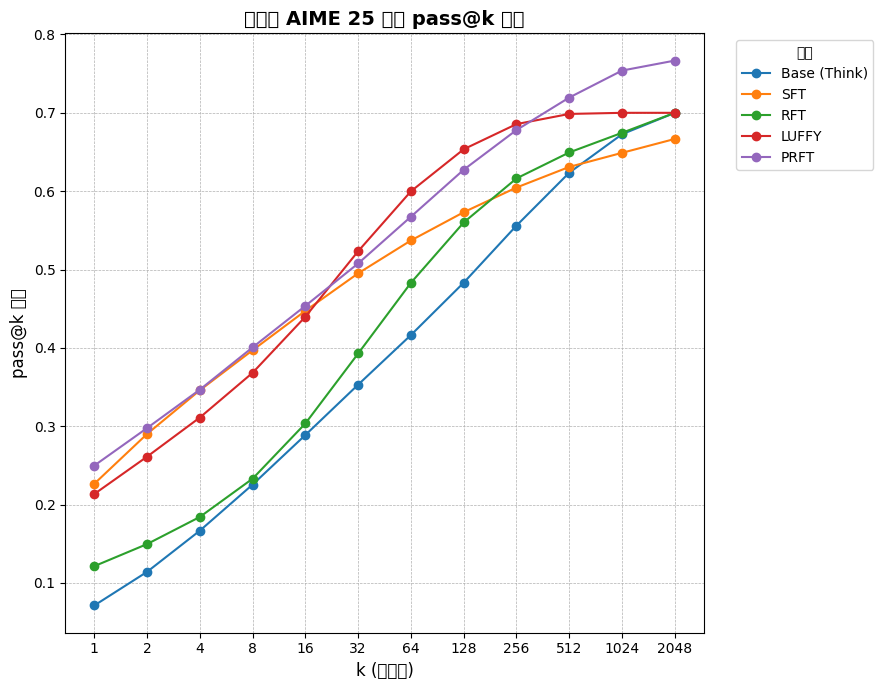

In [15]:
import math
import json
from collections import defaultdict
import matplotlib.pyplot as plt
import os # 导入 os 模块以进行文件检查

# --- 1. 用户提供的设置和功能 ---

# 尝试加载 AIME 问题定义文件
try:
    with open("aime_problems.json", "r") as f:
        aime_problems = json.load(f)
    print("成功加载 'aime_problems.json'。")
except FileNotFoundError:
    print("错误: 'aime_problems.json' 未找到。")
    print("请确保该文件与脚本在同一目录中。")
    print("将使用空的问题列表继续，这可能导致 pass@k 为 0。")
    aime_problems = {"aime24": [], "aime25": []} # 使用空数据以避免崩溃
except json.JSONDecodeError:
    print("错误: 'aime_problems.json' 文件格式不正确，无法解析。")
    exit() # 无法继续，退出脚本

def is_aime24_problem(input_text):
    """检查输入是否为 AIME 24 问题"""
    for problem in aime_problems["aime24"]:
        if problem in input_text:
            return True
    return False

def is_aime25_problem(input_text):
    """检查输入是否为 AIME 25 问题"""
    for problem in aime_problems["aime25"]:
        if problem in input_text:
            return True
    return False

def calculate_pass_at_k(c_list, n_samples, k_list):
    """
    (用户提供的函数 - 未修改)
    根据论文 (arXiv:2504.13837v4) 附录 A.2 中的公式计算 pass@k 的无偏估计。
    """
    
    # 检查 c_list 是否为空
    num_problems = len(c_list)
    if num_problems == 0:
        print("  ... 警告: c_list 为空，没有找到匹配的问题。将返回 0。")
        return {k: 0.0 for k in k_list if isinstance(k, int) and k >= 0}

    # 检查 c_list 中的值是否有效
    for c_i in c_list:
        if not isinstance(c_i, int) or c_i < 0 or c_i > n_samples:
            if not isinstance(c_i, int) or c_i < 0:
                 raise ValueError(f"c_list 中的值 ({c_i}) 必须是非负整数。")
            if c_i > n_samples:
                 print(f"  ... 警告: c_list 中的值 ({c_i}) 大于 n_samples ({n_samples})。")
            
    results = {}
    
    # 遍历所有需要计算的 k 值
    for k in k_list:
        if not isinstance(k, int) or k < 0:
            print(f"  ... 跳过无效的 k 值: {k} (必须是非负整数)")
            continue
            
        if k > n_samples:
            # (已在 get_pass_at_k_scores 中处理，此处保留)
            results[k] = None
            continue
            
        if k == 0:
            results[k] = 0.0
            continue
            
        try:
            denominator = math.comb(n_samples, k)
        except ValueError:
            print(f"  ... 计算 C({n_samples}, {k}) 出错。跳过 k={k}。")
            results[k] = None
            continue
            
        if denominator == 0:
            print(f"  ... 分母 C({n_samples}, {k}) 为 0。跳过 k={k}。")
            results[k] = None
            continue

        total_pass_at_k_for_dataset = 0.0
        
        for c_i in c_list:
            num_incorrect = n_samples - c_i
            numerator = math.comb(num_incorrect, k)
            pass_at_k_for_problem = 1.0 - (numerator / denominator)
            total_pass_at_k_for_dataset += pass_at_k_for_problem
            
        average_pass_at_k = total_pass_at_k_for_dataset / num_problems
        results[k] = average_pass_at_k
        
    return results

# --- 2. 定义所有模型和路径 ---

base_file_paths = [
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-16k-think_aime2425_512_luffy_step__25-11-15-Nov-11-1763143255/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-16k-think_aime2425_512_luffy_step__25-11-15-Nov-11-1763152408/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-16k-think_aime2425_512_luffy_step__25-11-15-Nov-11-1763155828/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-16k-think_aime2425_512_luffy_step__25-11-15-Nov-11-1763159266/0.jsonl"
]
sft_file_paths = [
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-SFT_aime2425_512_luffy_step__25-11-14-Nov-11-1763121249/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-SFT_aime2425_512_luffy_step__25-11-15-Nov-11-1763178296/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-SFT_aime2425_512_luffy_step__25-11-15-Nov-11-1763203067/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_Qwen2.5-Math-7B-SFT_aime2425_512_luffy_step__25-11-16-Nov-11-1763239655/0.jsonl"
]
rft_file_paths = [
    "/home/ma-user/work/hzy-dev/_results/eval_rft_baseline_aime2425_512_step_global_step_500_25-11-16-Nov-11-1763261202/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/eval_rft_baseline_aime2425_512_step_global_step_500_25-11-16-Nov-11-1763265067/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/eval_rft_baseline_aime2425_512_step_global_step_500_25-11-16-Nov-11-1763269031/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/eval_rft_baseline_aime2425_512_step_global_step_500_25-11-16-Nov-11-1763273029/0.jsonl"
]
luffy_file_paths = [
    "/home/ma-user/work/hzy-dev/_results/luffyeval_LUFFY-Qwen-Math-7B-Zero_aime2425_512_luffy_step__25-11-15-Nov-11-1763136772/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_LUFFY-Qwen-Math-7B-Zero_aime2425_512_luffy_step__25-11-15-Nov-11-1763212366/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_LUFFY-Qwen-Math-7B-Zero_aime2425_512_luffy_step__25-11-15-Nov-11-1763213316/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/luffyeval_LUFFY-Qwen-Math-7B-Zero_aime2425_512_luffy_step__25-11-15-Nov-11-1763216029/0.jsonl"
]
prft_file_paths = [
    "/home/ma-user/work/hzy-dev/_results/eval_prft_aime2425_512_step_global_step_500_25-11-14-Nov-11-1763060067/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/eval_prft_aime2425_512_step_global_step_500_25-11-15-Nov-11-1763162923/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/eval_prft_aime2425_512_step_global_step_500_25-11-15-Nov-11-1763187543/0.jsonl",
    "/home/ma-user/work/hzy-dev/_results/eval_prft_aime2425_512_step_global_step_500_25-11-16-Nov-11-1763224007/0.jsonl"
]

# 组织模型
MODELS = {
    "Base (Think)": base_file_paths,
    "SFT": sft_file_paths,
    "RFT": rft_file_paths,
    "LUFFY": luffy_file_paths,
    "PRFT": prft_file_paths
}

# 组织过滤器
FILTERS = {
    "AIME 24": is_aime24_problem,
    "AIME 25": is_aime25_problem
}

# --- 3. 定义常量和新的处理函数 ---

K_LIST = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048]
SAMPLES_PER_FILE = 512

# ⭐ 新增：定义结果缓存文件名
RESULTS_FILENAME = "all_pass_at_k_results.json"


def get_pass_at_k_scores(file_paths, filter_func, n_per_file, k_list_to_calc):
    """
    加载所有文件，按指定函数过滤，并计算 pass@k 分数。
    """
    results_by_problem = defaultdict(list)
    total_lines_checked = 0
    missing_files = 0
    
    for file_path in file_paths:
        if not os.path.exists(file_path):
            print(f"  ... 警告: 文件未找到 {file_path}，已跳过。")
            missing_files += 1
            continue
        
        try:
            with open(file_path, 'r') as f:
                for line in f:
                    try:
                        d = json.loads(line)
                        total_lines_checked += 1
                        if 'input' in d and 'score' in d:
                            if filter_func(d['input']):
                                results_by_problem[d['input']].append(d["score"])
                        else:
                            print(f"  ... 警告: 跳过 {file_path} 中的无效行 (缺少 'input' 或 'score')。")
                    except json.JSONDecodeError:
                        print(f"  ... 警告: 跳过 {file_path} 中的无效 JSON 行。")
        except Exception as e:
            print(f"  ... 错误: 读取文件 {file_path} 时出错: {e}")

    print(f"  ... 检查了 {total_lines_checked} 行，找到 {len(results_by_problem)} 个匹配的问题。")

    if not results_by_problem:
        print("  ... 未找到此过滤器的匹配数据。")
        return {k: 0.0 for k in k_list_to_calc}

    c_values = [int(sum(v)) for v in results_by_problem.values()]
    n_samples_list = [len(v) for v in results_by_problem.values()]
    
    num_valid_files = len(file_paths) - missing_files
    if num_valid_files == 0:
        print("  ... 错误: 所有文件都缺失，无法计算。")
        return {k: 0.0 for k in k_list_to_calc}

    expected_n_samples = n_per_file * num_valid_files
    n_samples = 0
    
    if not n_samples_list:
        n_samples = expected_n_samples
    elif len(set(n_samples_list)) > 1:
        print(f"  ... 警告: 每个问题的样本数不一致: {set(n_samples_list)}")
        print(f"  ... 将使用预期的样本数 n_samples = {expected_n_samples} (基于 {num_valid_files} 个文件)。")
        n_samples = expected_n_samples
    elif n_samples_list[0] != expected_n_samples:
        print(f"  ... 警告: 实际样本数 ({n_samples_list[0]}) 与预期 ({expected_n_samples}) 不符。")
        n_samples = n_samples_list[0]
        print(f"  ... 将使用实际的 n_samples = {n_samples}。")
    else:
        n_samples = expected_n_samples
        print(f"  ... 已验证 {len(c_values)} 个问题，每个问题有 {n_samples} 个样本。")

    valid_k_list = [k for k in k_list_to_calc if k <= n_samples]
    if len(valid_k_list) != len(k_list_to_calc):
        print(f"  ... 注意: k 值 > n_samples ({n_samples}) 将被跳过。")
        
    pass_at_k_scores = calculate_pass_at_k(c_values, n_samples, valid_k_list)
    
    for k in k_list_to_calc:
        if k not in pass_at_k_scores:
             pass_at_k_scores[k] = None

    return pass_at_k_scores

# --- 4. 主执行循环 (⭐ 已修改) ---

# 检查缓存文件是否存在
if os.path.exists(RESULTS_FILENAME):
    print(f"--- 正在从 '{RESULTS_FILENAME}' 加载缓存结果 ---")
    try:
        with open(RESULTS_FILENAME, 'r') as f:
            loaded_data = json.load(f)
        
        # 修复 JSON 键（JSON 保存时整数键会变字符串 "1"，加载时需转回整数 1）
        all_results = {}
        for dataset_name, model_scores in loaded_data.items():
            all_results[dataset_name] = {}
            for model_name, scores in model_scores.items():
                # 使用字典推导式将字符串键转回整数
                int_key_scores = {int(k): v for k, v in scores.items()}
                all_results[dataset_name][model_name] = int_key_scores
                
        print(f"✅ 缓存加载成功。跳过计算，直接生成报告。")

    except Exception as e:
        print(f"  ... 错误: 加载缓存文件失败: {e}。将重新计算。")
        all_results = None # 标记为失败，以便执行 'else' 块
else:
    print(f"--- 未找到缓存文件 '{RESULTS_FILENAME}'。将开始计算... ---")
    all_results = None # 标记为未加载

if all_results is None: # 如果加载失败或文件不存在，则执行计算
    all_results = defaultdict(dict) # 结构: {dataset: {model: {k: score}}}

    print("========= 开始计算 pass@k 分数 =========")
    
    for dataset_name, filter_func in FILTERS.items():
        print(f"\n--- Zz正在处理数据集: {dataset_name} ---")
        for model_name, files in MODELS.items():
            print(f"计算模型: {model_name}...")
            scores = get_pass_at_k_scores(files, filter_func, SAMPLES_PER_FILE, K_LIST)
            all_results[dataset_name][model_name] = scores

    print("\n========= 计算完成 =========")
    
    # ⭐ 新增：保存结果到文件
    print(f"\n--- 正在保存结果到 '{RESULTS_FILENAME}' ---")
    try:
        # 在保存时，all_results 仍然是 defaultdict，json.dump 会将其作为常规 dict 处理
        with open(RESULTS_FILENAME, 'w') as f:
            json.dump(all_results, f, indent=4)
        print(f"✅ 结果已成功保存。")
    except Exception as e:
        print(f"  ... 错误: 保存结果失败: {e}")


# --- 5. 生成 Markdown 表格 ---

print("\n========= 开始生成报告 =========")
for dataset_name, model_scores in all_results.items():
    print(f"\n## 📊 总结表格: {dataset_name}\n")
    
    # 创建表头
    header_k = [f"pass@{k}" for k in K_LIST]
    header = f"| 模型 | " + " | ".join(header_k) + " |"
    separator = "|:---| " + " | ".join([":---" for _ in header_k]) + " |"
    
    print(header)
    print(separator)
    
    # 创建数据行
    for model_name, scores in model_scores.items():
        row = f"| **{model_name}** |"
        for k in K_LIST:
            # 使用 scores.get(k) 确保键存在（即使是从 JSON 加载的）
            score = scores.get(k) 
            if score is not None:
                row += f" {score:.4f} |"
            else:
                row += " N/A |" # 如果 k > n_samples
        print(row)

# --- 6. 生成图表 ---

for dataset_name, model_scores in all_results.items():
    print(f"\n正在为 {dataset_name} 生成图表...")
    
    plt.figure(figsize=(11, 7))
    
    for model_name, scores in model_scores.items():
        # 获取有效的 (k, score) 对
        k_values = [k for k in K_LIST if scores.get(k) is not None]
        pass_rates = [scores[k] for k in k_values]
        
        if k_values: # 仅在有数据时绘图
            plt.plot(k_values, pass_rates, marker='o', linestyle='-', label=model_name)

    plt.xscale('log', base=2)
    plt.xlabel('k (样本数)', fontsize=12)
    plt.ylabel('pass@k 分数', fontsize=12)
    plt.title(f'模型在 {dataset_name} 上的 pass@k 表现', fontsize=14, weight='bold')
    
    plot_ticks = [k for k in K_LIST if any(m.get(k) is not None for m in model_scores.values())]
    if plot_ticks:
        plt.xticks(plot_ticks, labels=[str(k) for k in plot_ticks])
    
    plt.gca().xaxis.set_major_formatter(plt.ScalarFormatter())
    
    plt.legend(bbox_to_anchor=(1.04, 1), loc="upper left", title="模型")
    
    plt.grid(True, which="both", linestyle='--', linewidth=0.5)
    plt.tight_layout(rect=[0, 0, 0.82, 1])
    
    # 保存图表
    plot_filename = f"{dataset_name.replace(' ', '_')}_pass_at_k.png"
    plt.savefig(plot_filename)
    print(f"✅ 图表已保存为: {plot_filename}")

print("\n========= 脚本执行完毕 =========")